In [ ]:
import os
import random
import time
from pathlib import Path
from collections import defaultdict

import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, Subset
from torchvision.datasets import ImageFolder
from torchvision import transforms
from torchvision.models import resnet50
from PIL import Image
from tqdm import tqdm
import matplotlib.pyplot as plt
import seaborn as sns

from huggingface_hub import hf_hub_download
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report
import kagglehub

In [ ]:
torch.manual_seed(42)
random.seed(42)
np.random.seed(42)

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Using device:", device)

# --- dataset download (unchanged) ---
path = kagglehub.dataset_download("paultimothymooney/chest-xray-pneumonia")
print("Dataset path:", path)

data_root = Path(path)
base_dir = data_root / "chest_xray" if (data_root / "chest_xray").exists() else data_root
train_dir = base_dir / "train"
test_dir = base_dir / "test"

Using device: cuda
Using Colab cache for faster access to the 'chest-xray-pneumonia' dataset.
Dataset path: /kaggle/input/chest-xray-pneumonia


In [ ]:
image_size = 224
batch_size = 64
num_workers = 4 if torch.cuda.is_available() else 2

train_transform = transforms.Compose([
    transforms.Resize((image_size, image_size)),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std=[0.229, 0.224, 0.225]),
])

eval_transform = transforms.Compose([
    transforms.Resize((image_size, image_size)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std=[0.229, 0.224, 0.225]),
])

In [ ]:
full_train_dataset = ImageFolder(train_dir, transform=train_transform)
targets = full_train_dataset.targets
indices = list(range(len(targets)))

# stratified split for train/val
train_idx, val_idx = train_test_split(
    indices,
    test_size=0.10,
    stratify=targets,
    random_state=42
)
class_to_train_indices = defaultdict(list)
for idx in train_idx:
    label = targets[idx]
    class_to_train_indices[label].append(idx)

# Decide target size (undersample to minority class count)
min_count = min(len(idxs) for idxs in class_to_train_indices.values())
print("Per-class counts BEFORE downsampling:", {k: len(v) for k, v in class_to_train_indices.items()})
print("Downsampling each class to:", min_count)

balanced_train_idx = []
for cls, idxs in class_to_train_indices.items():
    if len(idxs) > min_count:
        sampled = random.sample(idxs, min_count)
    else:
        sampled = list(idxs)
    balanced_train_idx.extend(sampled)

random.shuffle(balanced_train_idx)
print("Balanced train size:", len(balanced_train_idx))

# Create datasets/loaders:
# Important: full_train_dataset must be the ImageFolder built from train_dir (same class ordering)
train_dataset = Subset(full_train_dataset, balanced_train_idx)

# Validation uses the original (not-balanced) indices and eval_transform
val_dataset = Subset(ImageFolder(train_dir, transform=eval_transform), val_idx)

# Test unchanged
test_dataset = ImageFolder(test_dir, transform=eval_transform)

print(f"Train size: {len(train_dataset)}")
print(f"Val size:   {len(val_dataset)}")
print(f"Test size:  {len(test_dataset)}")

class_names = full_train_dataset.classes
num_classes = len(class_names)
print("Classes:", class_names)

Per-class counts BEFORE downsampling: {1: 3487, 0: 1207}
Downsampling each class to: 1207
Balanced train size: 2414
Train size: 2414
Val size:   522
Test size:  624
Classes: ['NORMAL', 'PNEUMONIA']


In [ ]:

train_loader = DataLoader(
    train_dataset, batch_size=batch_size,
    shuffle=True, num_workers=num_workers
)

val_loader = DataLoader(
    val_dataset, batch_size=batch_size,
    shuffle=False, num_workers=num_workers
)

test_loader = DataLoader(
    test_dataset, batch_size=batch_size,
    shuffle=False, num_workers=num_workers
)

/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py:627: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  warnings.warn(


In [ ]:
backbone = resnet50(pretrained=False)
# Adapt stem to smaller-kernel config (same as your original)
backbone.conv1 = nn.Conv2d(3, 64, 3, 1, 1, bias=False)
backbone.maxpool = nn.Identity()
feat_dim = backbone.fc.in_features
backbone.fc = nn.Identity()

# load pretrained SimCLR weights (only those matching backbone)
ckpt_path = hf_hub_download(
    repo_id="edadaltocg/resnet50_simclr_cifar100",
    filename="pytorch_model.bin"
)
state_dict = torch.load(ckpt_path, map_location="cpu")
state_dict = {
    k.replace("backbone.", ""): v
    for k, v in state_dict.items()
    if k.replace("backbone.", "") in backbone.state_dict()
}
backbone.load_state_dict(state_dict, strict=False)
backbone = backbone.to(device)
print("✅ CIFAR SimCLR backbone loaded")

/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=None`.
  warnings.warn(msg)


✅ CIFAR SimCLR backbone loaded


In [ ]:
class PartialFineTuneModel(nn.Module):
    def __init__(self, backbone, feature_dim, num_classes, dropout_p=0.5):
        super().__init__()
        self.backbone = backbone

        # Freeze entire backbone parameters first
        for p in self.backbone.parameters():
            p.requires_grad = False

        # Unfreeze only the last ResNet block (layer4)
        for p in self.backbone.layer4.parameters():
            p.requires_grad = True

        # Put BatchNorm layers in backbone into eval mode and freeze their params
        # to avoid updating running stats with small fine-tune batches.
        for m in self.backbone.modules():
            if isinstance(m, nn.BatchNorm2d):
                m.eval()
                for p in m.parameters():
                    p.requires_grad = False

        # small classifier with dropout to reduce overfitting
        self.classifier = nn.Sequential(
            nn.Dropout(dropout_p),
            nn.Linear(feature_dim, num_classes)
        )

    def forward(self, x):
        features = self.backbone(x)
        return self.classifier(features)

model = PartialFineTuneModel(backbone, feat_dim, num_classes, dropout_p=0.5).to(device)

In [ ]:
criterion = nn.CrossEntropyLoss()

# OPTIMIZER: use smaller LR for layer4 (safer) and moderate LR for classifier
optimizer = torch.optim.Adam(
    [
        {"params": model.backbone.layer4.parameters(), "lr": 5e-5},  # reduced
        {"params": model.classifier.parameters(), "lr": 5e-4},
    ],
    weight_decay=5e-5
)

# scheduler (robust to different PyTorch versions)
try:
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, mode='min', factor=0.5, patience=1, verbose=True
    )
except TypeError:
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, mode='min', factor=0.5, patience=1
    )

In [ ]:
def evaluate(model, loader):
    model.eval()
    total_loss, correct, total = 0.0, 0, 0
    with torch.no_grad():
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            logits = model(xb)
            loss = criterion(logits, yb)

            total_loss += loss.item() * xb.size(0)
            correct += (logits.argmax(1) == yb).sum().item()
            total += xb.size(0)

    return total_loss / total, correct / total

In [ ]:
epochs = 6                # max epochs
early_stopping_patience = 5 # number of epochs with no improvement to stop
min_delta = 1e-4            # minimum decrease in val_loss to count as improvement
min_epochs = 5              # don't early-stop before this many epochs
save_path = "checkpoints/best_model.pt"
restore_best = True         # after training, load the best checkpoint

# Storage for plotting/logging
train_losses = []
val_losses = []
val_accs = []

best_val_loss = float("inf")
best_epoch = -1
epochs_no_improve = 0

start_time = time.time()

for epoch in range(epochs):
    epoch_start = time.time()

    # ---------- TRAINING ----------
    model.train()
    running_loss = 0.0
    n_batches = 0

    pbar = tqdm(train_loader, desc=f"Epoch {epoch+1}/{epochs}")
    for xb, yb in pbar:
        xb, yb = xb.to(device), yb.to(device)

        logits = model(xb)
        loss = criterion(logits, yb)

        if torch.isnan(loss):
            raise RuntimeError(f"NaN loss encountered at epoch {epoch+1}")

        optimizer.zero_grad()
        loss.backward()

        # Clip grads for stability
        torch.nn.utils.clip_grad_norm_(
            [p for p in model.parameters() if p.requires_grad], max_norm=1.0
        )

        optimizer.step()

        running_loss += loss.item()
        n_batches += 1
        pbar.set_postfix(train_loss=(running_loss / n_batches))

    train_loss = running_loss / (n_batches if n_batches > 0 else 1)

    # ---------- VALIDATION ----------
    model.eval()
    val_running_loss = 0.0
    val_correct = 0
    val_total = 0
    with torch.no_grad():
        for xb, yb in val_loader:
            xb, yb = xb.to(device), yb.to(device)
            logits = model(xb)
            loss = criterion(logits, yb)

            val_running_loss += loss.item() * xb.size(0)
            val_correct += (logits.argmax(1) == yb).sum().item()
            val_total += xb.size(0)

    val_loss = val_running_loss / (val_total if val_total > 0 else 1)
    val_acc = val_correct / (val_total if val_total > 0 else 1)

    # Step scheduler if present (works with ReduceLROnPlateau)
    try:
        if "scheduler" in globals() and scheduler is not None:
            # For ReduceLROnPlateau, pass val_loss; other schedulers may ignore the argument.
            try:
                scheduler.step(val_loss)
            except TypeError:
                # Some schedulers expect no argument
                scheduler.step()
    except Exception as e:
        print("Warning: scheduler step failed:", e)

    # ---------- LOGGING ----------
    train_losses.append(train_loss)
    val_losses.append(val_loss)
    val_accs.append(val_acc)

    # compute gradient norm (last batch's grads after optimizer.step) for monitoring:
    grad_norm = 0.0
    for p in model.parameters():
        if p.grad is not None:
            grad_norm += float(p.grad.data.norm(2).item() ** 2)
    grad_norm = grad_norm ** 0.5

    # current LRs
    try:
        lrs = [float(g['lr']) for g in optimizer.param_groups]
    except Exception:
        lrs = ["-"]

    epoch_time = time.time() - epoch_start
    print(
        f"Epoch {epoch+1}/{epochs} "
        f"TrainLoss={train_loss:.4f} ValLoss={val_loss:.4f} ValAcc={val_acc:.4f} "
        f"LRs={lrs} GradNorm={grad_norm:.4f} EpochTime={epoch_time:.1f}s"
    )

    # ---------- EARLY STOPPING CHECK ----------
    improved = (val_loss + min_delta) < best_val_loss  # require improvement by min_delta
    if improved:
        best_val_loss = val_loss
        best_epoch = epoch + 1
        epochs_no_improve = 0
        # Save best model
        torch.save(model.state_dict(), save_path)
        print(f"  -> Validation loss improved. Saved best model to {save_path}")
    else:
        epochs_no_improve += 1
        print(f"  -> No improvement for {epochs_no_improve} / {early_stopping_patience} epochs")

    # If we've seen enough epochs without improvement, stop
    if (epochs_no_improve >= early_stopping_patience) and (epoch + 1 >= min_epochs):
        print(f"Early stopping triggered. No improvement for {epochs_no_improve} epochs.")
        break

total_time = time.time() - start_time
print("\n==============================")
print(f"Total training time: {total_time/60:.2f} minutes")
print(f"Best val loss: {best_val_loss:.4f} at epoch {best_epoch}")
print("==============================\n")

Epoch 1/6: 100%|██████████| 38/38 [02:30<00:00,  3.95s/it, train_loss=0.502]


Epoch 1/6 TrainLoss=0.5021 ValLoss=0.3303 ValAcc=0.8640 LRs=[5e-05, 0.0005] GradNorm=0.3416 EpochTime=178.7s
  -> Validation loss improved. Saved best model to checkpoints/best_model.pt


Epoch 2/6: 100%|██████████| 38/38 [02:44<00:00,  4.33s/it, train_loss=0.16]


Epoch 2/6 TrainLoss=0.1605 ValLoss=0.1171 ValAcc=0.9617 LRs=[5e-05, 0.0005] GradNorm=0.2171 EpochTime=195.4s
  -> Validation loss improved. Saved best model to checkpoints/best_model.pt


Epoch 3/6: 100%|██████████| 38/38 [02:44<00:00,  4.33s/it, train_loss=0.0913]


Epoch 3/6 TrainLoss=0.0913 ValLoss=0.0922 ValAcc=0.9655 LRs=[5e-05, 0.0005] GradNorm=0.2904 EpochTime=194.2s
  -> Validation loss improved. Saved best model to checkpoints/best_model.pt


... (2 outputs left out)

Epoch 5/6: 100%|██████████| 38/38 [02:47<00:00,  4.40s/it, train_loss=0.0397]


Epoch 5/6 TrainLoss=0.0397 ValLoss=0.0647 ValAcc=0.9770 LRs=[5e-05, 0.0005] GradNorm=0.4795 EpochTime=196.2s
  -> Validation loss improved. Saved best model to checkpoints/best_model.pt


Epoch 6/6: 100%|██████████| 38/38 [02:47<00:00,  4.40s/it, train_loss=0.0299]


Epoch 6/6 TrainLoss=0.0299 ValLoss=0.0664 ValAcc=0.9828 LRs=[5e-05, 0.0005] GradNorm=0.0543 EpochTime=196.3s
  -> No improvement for 1 / 5 epochs

Total training time: 19.29 minutes
Best val loss: 0.0647 at epoch 5



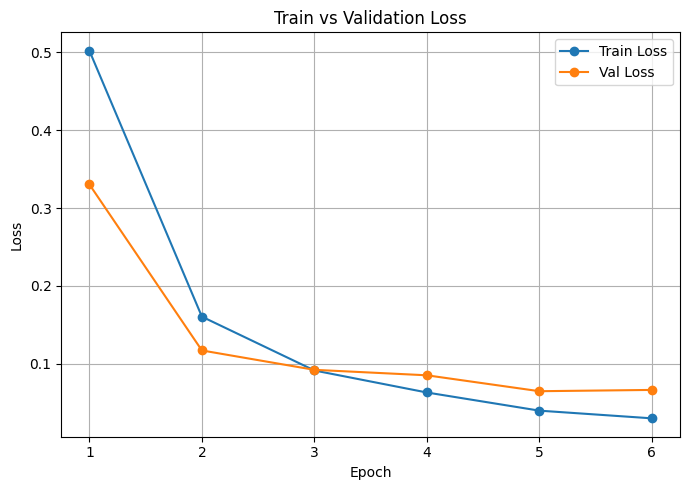

Saved loss plot to loss_curves_early_stopping.png


In [ ]:
plt.figure(figsize=(7,5))
plt.plot(np.arange(1, len(train_losses)+1), train_losses, label="Train Loss", marker='o')
plt.plot(np.arange(1, len(val_losses)+1), val_losses, label="Val Loss", marker='o')
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Train vs Validation Loss")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig("loss_curves_early_stopping.png", dpi=150)
plt.show()
print("Saved loss plot to loss_curves_early_stopping.png")

In [ ]:
test_loss, test_acc = evaluate(model, test_loader)
print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_acc:.4f}")

# --- Full test predictions + report + confusion matrix ---
model.eval()
all_preds, all_labels = [], []
with torch.no_grad():
    for xb, yb in test_loader:
        xb = xb.to(device)
        preds = model(xb).argmax(1).cpu().numpy()
        all_preds.extend(preds)
        all_labels.extend(yb.numpy())

print("\nClassification Report:\n")
print(classification_report(all_labels, all_preds, target_names=class_names))

Test Loss: 0.4744
Test Accuracy: 0.8301

Classification Report:

              precision    recall  f1-score   support

      NORMAL       0.98      0.56      0.71       234
   PNEUMONIA       0.79      0.99      0.88       390

    accuracy                           0.83       624
   macro avg       0.88      0.78      0.80       624
weighted avg       0.86      0.83      0.82       624



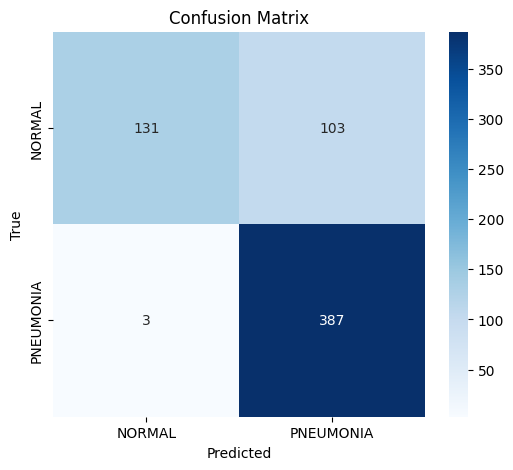

In [ ]:
cm = confusion_matrix(all_labels, all_preds)
plt.figure(figsize=(6,5))
sns.heatmap(
    cm, annot=True, fmt="d",
    xticklabels=class_names,
    yticklabels=class_names,
    cmap="Blues"
)
plt.xlabel("Predicted")
plt.ylabel("True")
plt.title("Confusion Matrix")
plt.show()


In [ ]:
os.makedirs("checkpoints", exist_ok=True)
torch.save(model.state_dict(), "checkpoints/linear_eval_simclr_cxr_balanced.pt")
print("✅ Model saved")


✅ Model saved
